In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!unzip -q '/content/drive/MyDrive/Colab Notebooks/malaria detection/archive.zip' -d '/content/dataset'

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Use MobileNextV2 model
from keras.applications import MobileNetV2
from keras.applications.mobilenet_v2 import preprocess_input
from keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input
from keras.losses import BinaryCrossentropy
from keras.models import Model
from keras.optimizers import Adam

In [ ]:
BATCH_SIZE = 32
IMG_SIZE = 128
DATA_DIR = '/content/dataset/cell_images/cell_images'
AUTO_TUNE = tf.data.AUTOTUNE

train_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='training',
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    DATA_DIR,
    validation_split=0.2,
    subset='validation',
    seed=123,
    image_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    label_mode='binary',
    shuffle=True
)

train_ds = train_ds.cache().prefetch(buffer_size=AUTO_TUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTO_TUNE)

Found 27558 files belonging to 2 classes.
Using 22047 files for training.
Found 27558 files belonging to 2 classes.
Using 5511 files for validation.


In [ ]:
# Build MobileNetV2 Transfer Learning Model
base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3),
                         include_top=False,
                         weights='imagenet')
base_model.trainable = False

input = Input(shape=(IMG_SIZE, IMG_SIZE, 3))

x = preprocess_input(input)
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
x = Dropout(0.5)(x)

output = Dense(1)(x)

model = Model(input, output)
model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,033 (8.93 MB)

 Trainable params: 82,049 (320.50 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
# Compile Model
model.compile(optimizer=Adam(learning_rate=0.001),
              loss=BinaryCrossentropy(from_logits=True),
              metrics=['accuracy'])

In [ ]:
# Train the Model
EPOCHS = 15
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    verbose=1
)

Epoch 1/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 53s 61ms/step - accuracy: 0.8860 - loss: 0.2645 - val_accuracy: 0.9296 - val_loss: 0.1855
Epoch 2/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9157 - loss: 0.2051 - val_accuracy: 0.9332 - val_loss: 0.1719
Epoch 3/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.9194 - loss: 0.1936 - val_accuracy: 0.9367 - val_loss: 0.1701
Epoch 4/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 11s 16ms/step - accuracy: 0.9241 - loss: 0.1863 - val_accuracy: 0.9363 - val_loss: 0.1714
Epoch 5/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9273 - loss: 0.1786 - val_accuracy: 0.9367 - val_loss: 0.1683
Epoch 6/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9283 - loss: 0.1745 - val_accuracy: 0.9399 - val_loss: 0.1652
Epoch 7/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - accuracy: 0.9318 - loss: 0.1698 - val_accuracy: 0.9352 - val_loss: 0.1701
Epoch 8/15
689/689 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9316 - loss: 0.1695 - va

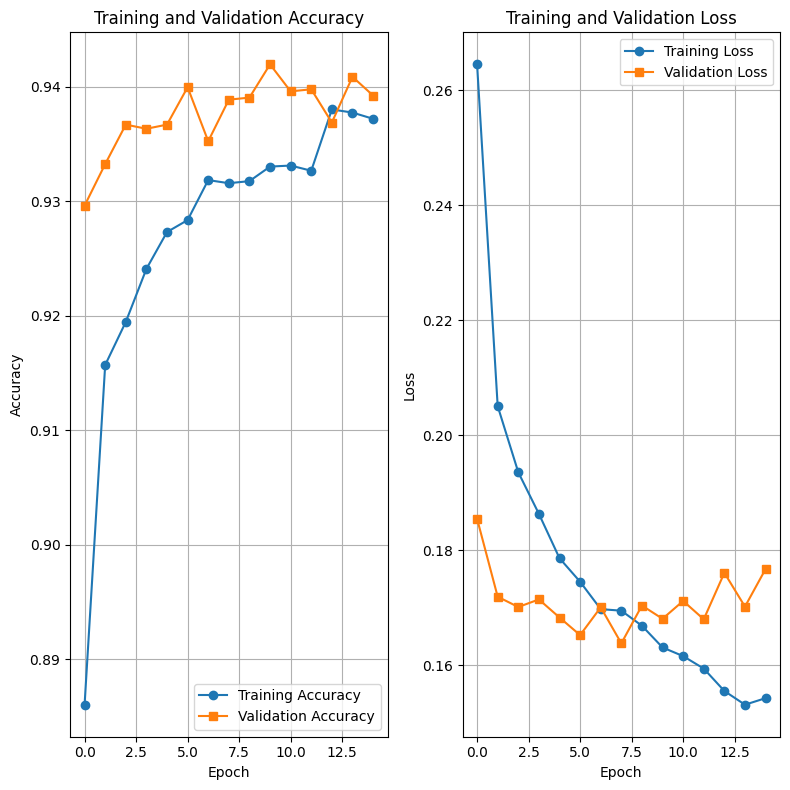

In [ ]:
# Extract metrics from training history
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

epochs_range = range(EPOCHS)

plt.figure(figsize=(8, 8))

# Plot Training & Validation Accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, accuracy, label='Training Accuracy', marker='o')
plt.plot(epochs_range, val_accuracy, label='Validation Accuracy', marker='s')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True)

# Plot Training & Validation Loss
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss', marker='o')
plt.plot(epochs_range, val_loss, label='Validation Loss', marker='s')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)

plt.tight_layout()
plt.show()

In [ ]:
# Save the trained model
model.save('/content/drive/MyDrive/Colab Notebooks/malaria detection/malaria_mobilenetv2_model.keras')
print("Model saved successfully!")

Model saved successfully!
